## Лабораторная работа № 1 
## Выполнение разведочного анализа больших данных с использованием фреймворка Apache Spark

### Часть 2

В данной части работы рассмотрены:
* разведочный анализ данных;
* работа с Dataframe API фреймворка `Apache Spark`.

Подключаем необходимые библиотеки.

In [1]:
import os
from pyspark.sql import SparkSession, DataFrame
from pyspark import SparkConf
from pyspark.sql.functions import (
    col, lit, sum, mean, when,
    explode, count, desc, floor,
    corr, array_contains, lit, first,
    size,
    trim,              
    regexp_replace     
)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Сформируем объект конфигурации для `Apache Spark`, указав необходимые параметры.

In [2]:
def create_spark_configuration() -> SparkConf:
    """
    Создает и конфигурирует экземпляр SparkConf для приложения Spark.

    Returns:
        SparkConf: Настроенный экземпляр SparkConf.
    """
    # Получаем имя пользователя
    user_name = os.getenv("USER")
    
    conf = SparkConf()
    conf.setAppName("Steam Games EDA")
    conf.setMaster("local[2]")
    conf.set("spark.submit.deployMode", "client")
    conf.set("spark.driver.memory", "4g")
    conf.set("spark.driver.cores", "2")
    conf.set("spark.executor.memory", "4g")
    conf.set("spark.executor.cores", "2")
    conf.set("spark.sql.shuffle.partitions", "4")
    conf.set("spark.sql.adaptive.enabled", "false")
    conf.set("spark.memory.fraction", "0.6")
    conf.set("spark.memory.storageFraction", "0.3")
    conf.set("spark.ui.enabled", "false")

    return conf

Создаём сам объект конфигурации.

In [3]:
conf = create_spark_configuration()

Создаём и выводим на экран сессию `Apache Spark`.

In [4]:
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

Прочитаем сохранённую в предыдущей части работы таблицу и загрузим её в `Spark Dataframe`.

In [5]:
df = spark.read.parquet("steam_games_cleaned.parquet")

Выведем прочитанную таблицу на экран.

In [6]:
df.show()

+-------+--------------------+------------+------------------+----------------+--------+--------+------------------+------------------------+---------------------+-------------------+------------+----------+--------------+--------------------+--------------------+--------------------+--------------------+
| app_id|                name|release_date|             price|estimated_owners|positive|negative|   recommendations|average_playtime_forever|steam_store_available|steam_spy_available|release_year|num_genres|num_categories|              genres|          developers|          publishers|          categories|
+-------+--------------------+------------+------------------+----------------+--------+--------+------------------+------------------------+---------------------+-------------------+------------+----------+--------------+--------------------+--------------------+--------------------+--------------------+
|1000130|       Cube Defender|  2019-01-06| 2.990000009536743|       0 - 20000|

Посмотрим на схему данных.

In [7]:
df.printSchema()

root
 |-- app_id: string (nullable = true)
 |-- name: string (nullable = true)
 |-- release_date: string (nullable = true)
 |-- price: double (nullable = true)
 |-- estimated_owners: string (nullable = true)
 |-- positive: double (nullable = true)
 |-- negative: double (nullable = true)
 |-- recommendations: double (nullable = true)
 |-- average_playtime_forever: double (nullable = true)
 |-- steam_store_available: boolean (nullable = true)
 |-- steam_spy_available: boolean (nullable = true)
 |-- release_year: integer (nullable = true)
 |-- num_genres: double (nullable = true)
 |-- num_categories: double (nullable = true)
 |-- genres: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- developers: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- publishers: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- categories: array (nullable = true)
 |    |-- element: string (containsNull = true)



Вычислим количество строк в датафрейме.

In [8]:
df.count()

129587

#### Анализ столбца `price`

Данный признак является **количественным**.

In [9]:
def count_nulls(data: DataFrame,
                column_name: str) -> None:
    """
    Подсчет количества null и not null значений в указанном столбце.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column_name (str): Имя столбца для подсчета null и not null значений.
    
    Returns:
        None
    """
    # Подсчет количества null значений в указанном столбце
    null_counts = data.select(
        sum(col(column_name).isNull().cast("int"))
    ).collect()[0][0]

    # Подсчет количества not null значений в указанном столбце
    not_null_counts = data.select(
        sum(col(column_name).isNotNull().cast("int"))
    ).collect()[0][0]

    # Вывод результатов
    print(f"Число колонок с NULL: {null_counts} "
          f"({100 * null_counts / (null_counts + not_null_counts):.2f}%)")

In [10]:
count_nulls(data=df, column_name="price")

Число колонок с NULL: 0 (0.00%)


Создадим функцию, позволяющую рассчитывать статистические показатели данных в столбцах и строить диаграмму "ящик с усами" для оценки наличия выбросов.

In [11]:
def plot_boxplots(data: DataFrame,
                  columns: list[str],
                  sample_fraction: float = 0.1) -> None:
    """
    Построение boxplot для нескольких столбцов в PySpark DataFrame.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        columns (list of str): Список имен столбцов для построения boxplot.
        sample_fraction (float): Доля данных для семплирования выбросов.
    
    Returns:
        None
    """
    box_data = []

    for column in columns:
        # Вычисление квантилей
        quantiles = data.approxQuantile(column, [0.25, 0.5, 0.75], 0.01)
        q1, median, q3 = quantiles

        # Вычисление IQR и границ усов
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        # Фильтрация выбросов
        filtered_df = data.filter((col(column) >= lower_bound) & (col(column) <= upper_bound))
        outliers_df = data.filter((col(column) < lower_bound) | (col(column) > upper_bound))

        # Вычисление минимального и максимального значений
        min_value = data.agg({column: "min"}).collect()[0][0]
        mean_value = data.agg({column: "mean"}).collect()[0][0]
        std_value = data.agg({column: "std"}).collect()[0][0]
        max_value = data.agg({column: "max"}).collect()[0][0]

        # Ограничение усов минимальным и максимальным значениями
        lower_bound = max(lower_bound, min_value)
        upper_bound = min(upper_bound, max_value)

        # Семплирование выбросов
        outliers = []
        if not outliers_df.isEmpty():
            sampled_outliers_df = outliers_df.sample(sample_fraction)
            outliers = (
                sampled_outliers_df
                .select(column)
                .limit(1000)
                .collect()
            )
            outliers = [row[column] for row in outliers]
            
            # Добавление минимального и максимального значений, если они 
            # относятся к выбросам и не присутствуют в семпле
            if min_value < lower_bound and min_value not in outliers:
                outliers.append(min_value)
            if max_value > upper_bound and max_value not in outliers:
                outliers.append(max_value)

        # Подготовка данных для axes.bxp
        box_data.append({
            'whislo': lower_bound,  # Нижняя граница усов
            'q1': q1,               # Первый квартиль
            'med': median,          # Медиана
            'q3': q3,               # Третий квартиль
            'whishi': upper_bound,  # Верхняя граница усов
            'fliers': outliers      # Выбросы
        })
        
    # Вывод статистических характеристик
    print(f"Минимальное значение:          {min_value:.2f}")
    print(f"Среднее значение:              {mean_value:.2f}")
    print(f"Среднеквадратичное отклонение: {std_value:.2f}")
    print(f"Первый квартиль:               {q1:.2f}")
    print(f"Медиана:                       {median:.2f}")
    print(f"Третий квартиль:               {q3:.2f}")
    print(f"Максимальное значение:         {max_value:.2f}")

    # Построение boxplot
    fig, ax = plt.subplots(figsize=(20, 6))
    ax.bxp(box_data, 
           vert=False, 
           positions=range(1, len(columns) + 1), widths=0.5)
    ax.set_yticks(range(1, len(columns) + 1))
    ax.set_yticklabels(columns)
    ax.set_xlabel('Value')
    ax.set_title('Boxplots')
    ax.grid(True)
    plt.show()

Минимальное значение:          0.00
Среднее значение:              9.55
Среднеквадратичное отклонение: 424.86
Первый квартиль:               1.99
Медиана:                       4.99
Третий квартиль:               9.99
Максимальное значение:         107500.00


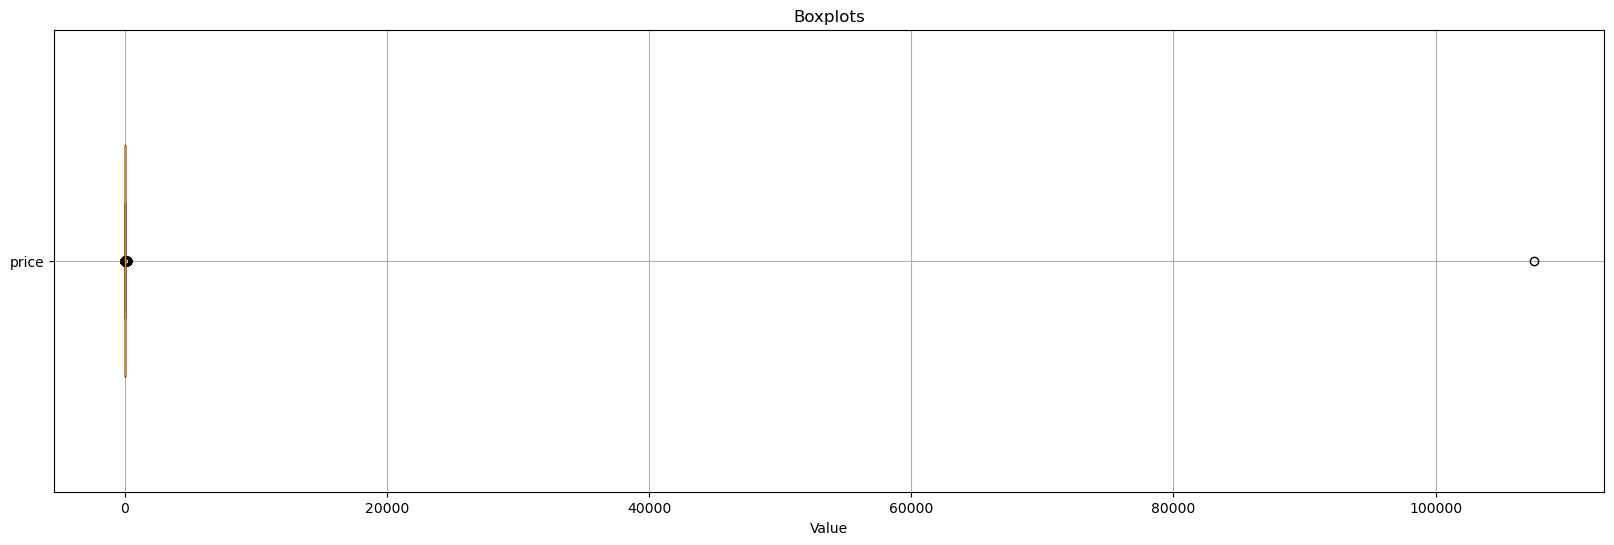

In [12]:
plot_boxplots(data=df, columns=["price"])

Ограничим цены для лучшей визуализации (исключим выбросы).

In [13]:
df = df.filter(col("price") <= 100)

Создадим функцию для визуализации распределения количественного признака.

In [14]:
def plot_quant_distribution(data: DataFrame,
                            column: str,
                            num_bins: int = 50) -> None:
    """Построение гистограммы для количественной переменной."""
    min_value = data.agg({column: "min"}).collect()[0][0]
    max_value = data.agg({column: "max"}).collect()[0][0]

    bin_size = (max_value - min_value) / num_bins

    data = data.withColumn(
        "bin", 
        floor((col(column) - min_value) / bin_size)
    )

    bin_counts = data.groupBy("bin").count()
    bin_counts_pd = bin_counts.limit(1000).toPandas()
    
    bin_edges = [min_value + i * bin_size for i in range(num_bins + 2)]
    bin_centers = [
        (bin_edges[i] + bin_edges[i + 1]) / 2 for i in range(num_bins + 1)
    ]
    
    bin_counts_pd['bin_center'] = bin_counts_pd['bin'].apply(
        lambda x: bin_centers[int(x)]
    )
    
    plt.figure(figsize=(20, 6))
    sns.histplot(data=bin_counts_pd, x="bin_center", 
                 weights="count", kde=True, bins=num_bins + 1)
    plt.xlabel("Value")
    plt.ylabel("Count")
    plt.title(f"Распределение количественного признака \"{column}\"")
    plt.grid(True)
    plt.show()

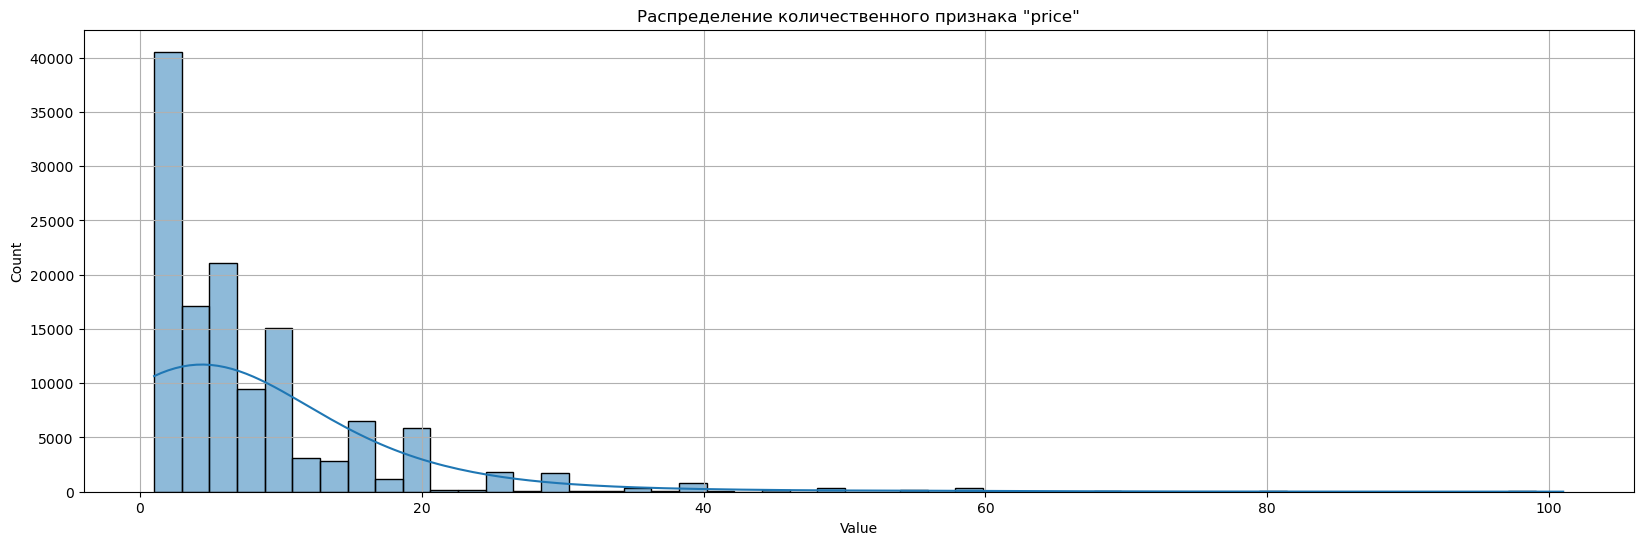

In [15]:
plot_quant_distribution(data=df, column="price")

#### Анализ столбца `genres`

Данный признак представляет собой **массив** жанров. Обработаем его, выделив самые популярные жанры.

In [16]:
def get_popular_genres(data: DataFrame, 
                        column: str, 
                        top_n: int = 10) -> DataFrame:
    """
    Получение DataFrame всех жанров, подсчет их количества, 
    сортировка по убыванию и вывод нескольких самых популярных жанров.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column (str): Имя столбца с массивом жанров.
        top_n (int): Количество самых популярных жанров для вывода.

    Returns:
        DataFrame: DataFrame с самыми популярными жанрами.
    """
    # Развертывание массива в отдельные строки
    exploded_df = data.withColumn("genre", explode(col(column)))

    # Подсчет количества каждого жанра
    genre_counts = (
        exploded_df
        .groupBy("genre")
        .agg(count("genre").alias("count"))
    )

    # Сортировка жанров по убыванию
    sorted_genres = genre_counts.orderBy(desc("count"))

    # Вывод нескольких самых популярных жанров
    top_genres = sorted_genres.limit(top_n)

    return top_genres

In [17]:
popular_genres = get_popular_genres(data=df, column="genres")
popular_genres.show()

+------------+-----+
|       genre|count|
+------------+-----+
|       Indie|92226|
|      Casual|57951|
|      Action|51598|
|   Adventure|50326|
|  Simulation|28140|
|    Strategy|26150|
|         RPG|23854|
|Free To Play|14182|
|Early Access|12834|
|      Sports| 5315|
+------------+-----+



Создадим функцию расчета и визуализации распределения категориальных признаков.

In [18]:
def plot_cat_distribution(data: DataFrame,
                          column_name: str,
                          top_n: int = 20,
                          is_array: bool = False) -> None:
    """
    Построение распределения категориального признака.
    Данные уже очищены в первой части.
    """
    if is_array:
        data = data.withColumn("element", explode(col(column_name)))
        group_column = "element"
    else:
        group_column = column_name
    
    categories = (
        data
        .groupBy(group_column)
        .count()
        .orderBy("count", ascending=False)
    )
    
    print(f"Количество категорий признака {column_name}: {categories.count()}")
    
    categories_pd = categories.limit(top_n).toPandas()
    
    plt.figure(figsize=(12, 6))
    sns.barplot(x=group_column, y="count", data=categories_pd)
    plt.title(f"Barplot of \"{column_name}\" counts")
    plt.xlabel(column_name)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

Количество категорий признака genres: 43


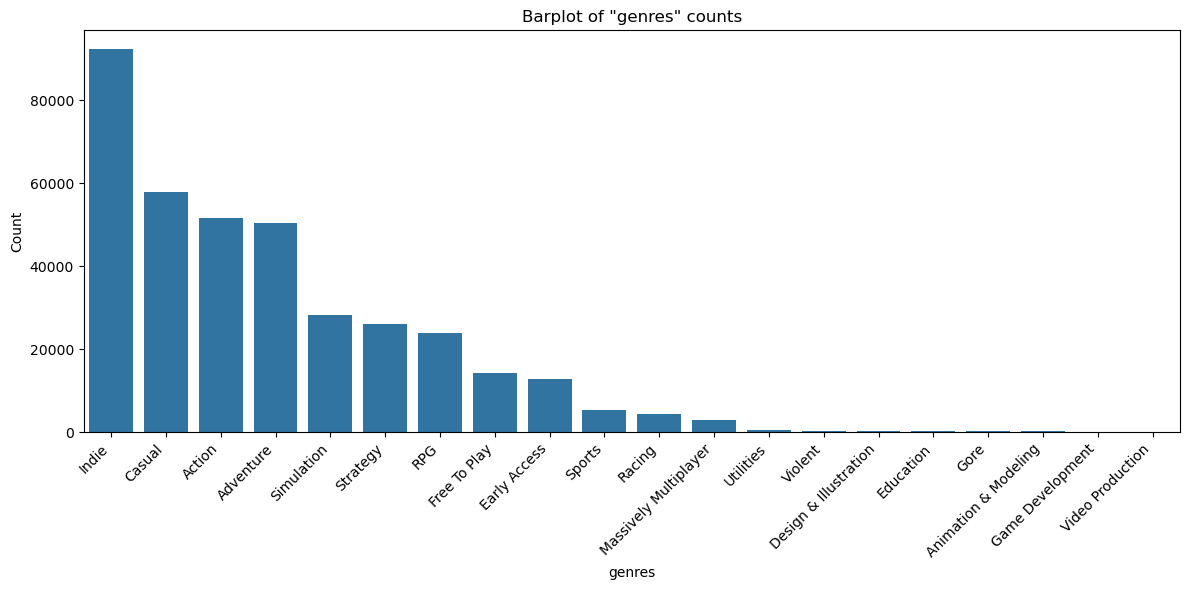

In [19]:
# Для столбца genres (массив)
plot_cat_distribution(data=df, column_name="genres", is_array=True)

# Для обычных категориальных столбцов
#plot_cat_distribution(data=df, column_name="genres", is_array=False)

#### Анализ столбца `positive` и `negative`

Данные признаки являются **количественными**. Рассчитаем процент положительных отзывов.

In [20]:
# Создаем столбец с процентом положительных отзывов
df = df.withColumn(
    "positive_ratio",
    when(
        (col("positive") + col("negative")) > 0,
        (col("positive") / (col("positive") + col("negative"))) * 100
    ).otherwise(0)
)

df.select("positive", "negative", "positive_ratio").show(10)

+--------+--------+-----------------+
|positive|negative|   positive_ratio|
+--------+--------+-----------------+
|     6.0|     1.0|85.71428571428571|
|   128.0|    25.0|83.66013071895425|
|   164.0|    69.0| 70.3862660944206|
|     5.0|     1.0|83.33333333333334|
|     1.0|     0.0|            100.0|
|   122.0|    73.0|62.56410256410256|
|     5.0|     2.0|71.42857142857143|
|     2.0|     6.0|             25.0|
|     3.0|     0.0|            100.0|
|    38.0|     3.0| 92.6829268292683|
+--------+--------+-----------------+
only showing top 10 rows



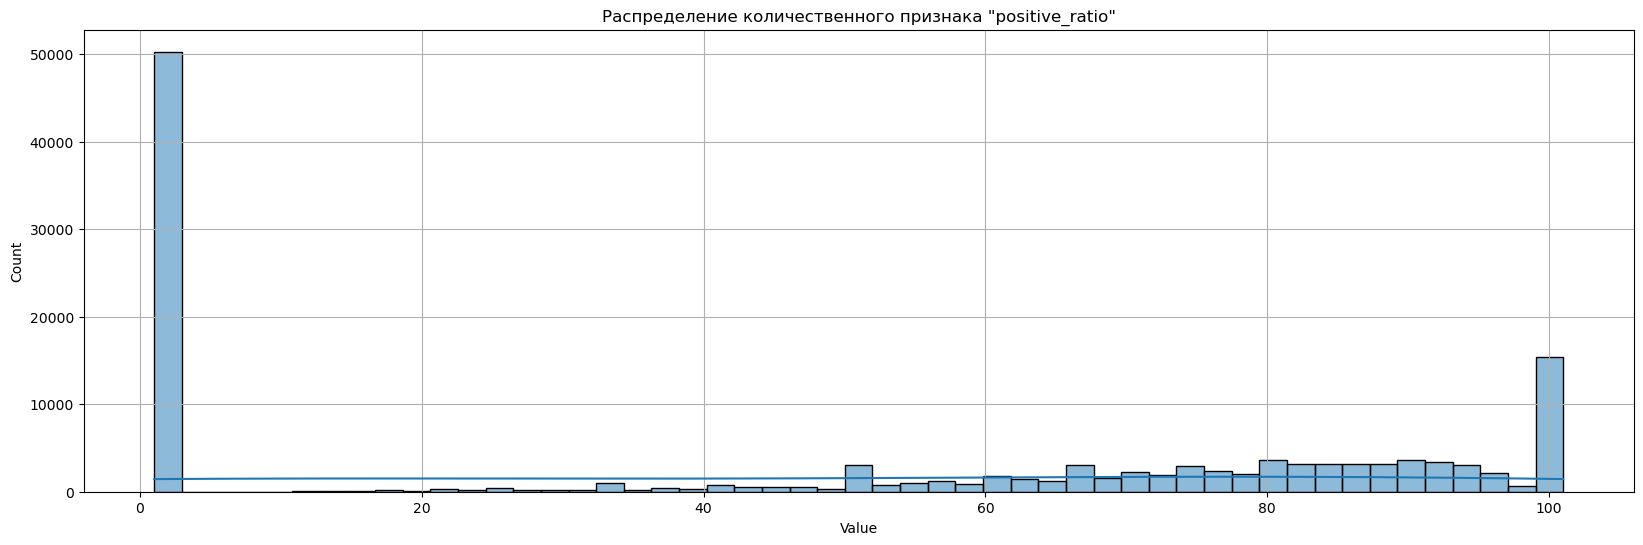

In [21]:
plot_quant_distribution(data=df, column="positive_ratio")

#### Анализ столбца `recommendations`

Признак **количественный**.

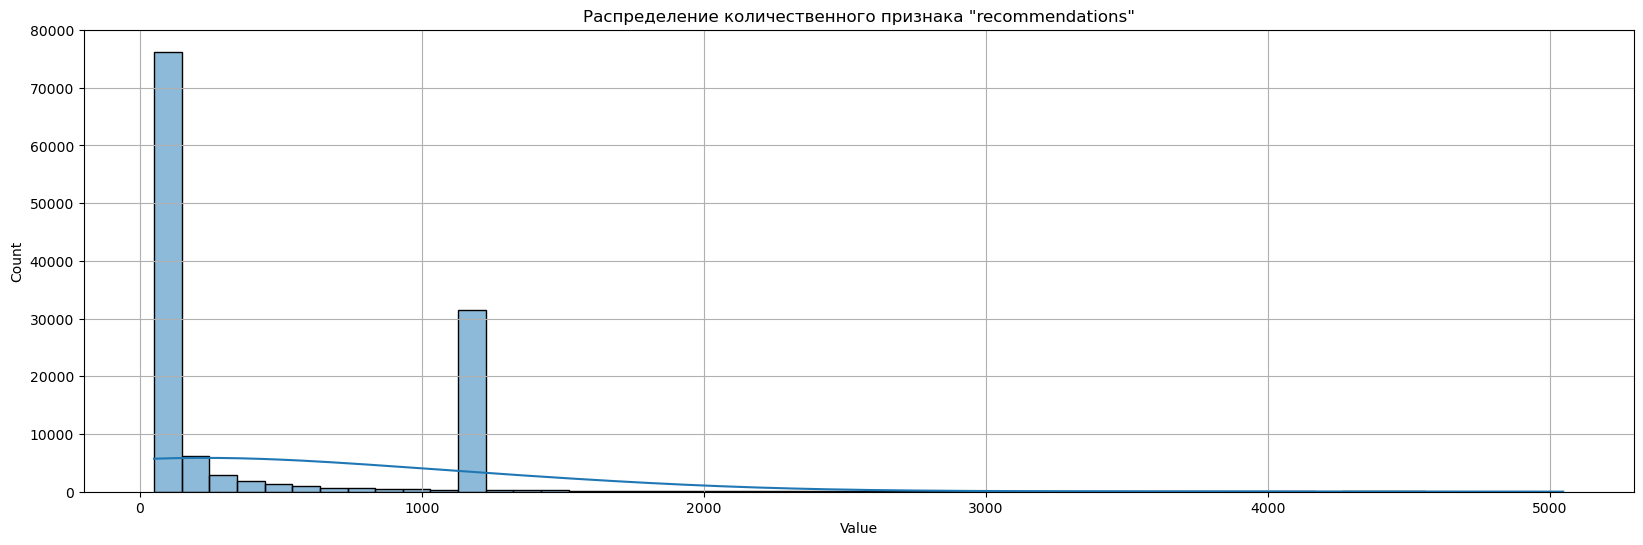

In [22]:
df = df.filter(col("recommendations") <= 5000)
plot_quant_distribution(data=df, column="recommendations")

#### Анализ столбца `average_playtime_forever`

Признак **количественный**.

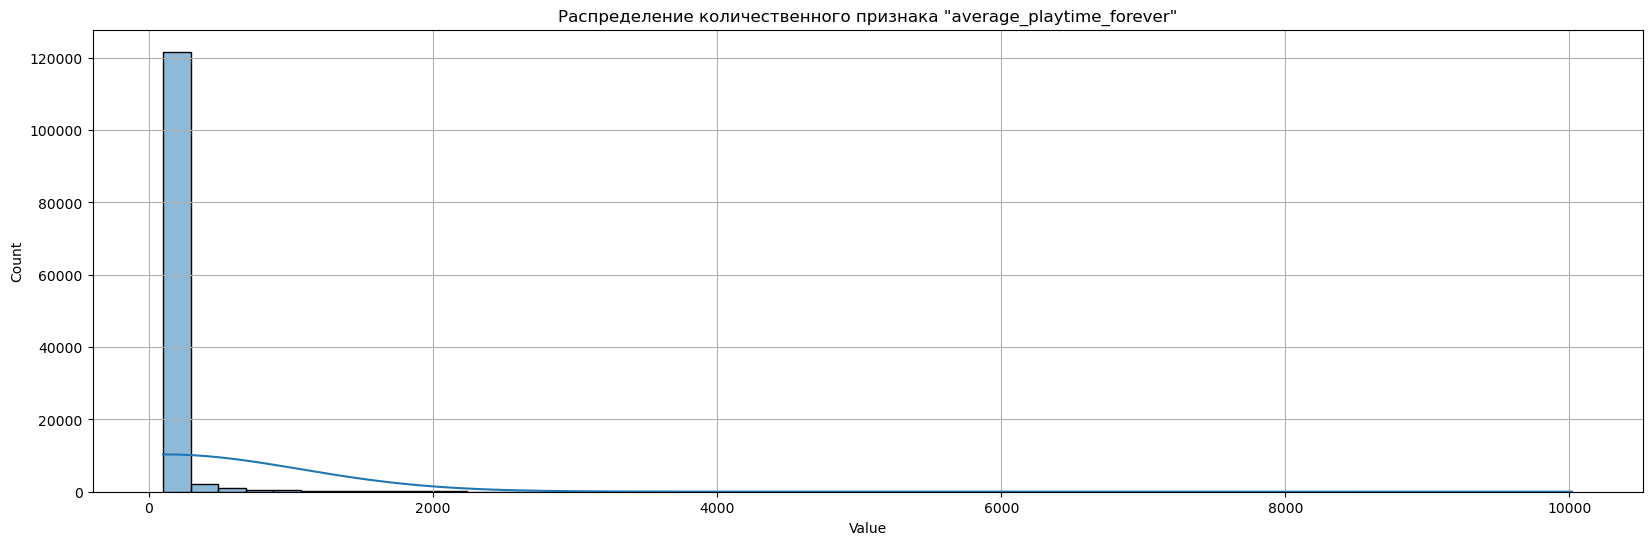

In [23]:
df = df.filter(col("average_playtime_forever") <= 10000)
plot_quant_distribution(data=df, column="average_playtime_forever")

#### Анализ столбца `release_year`

Признак **количественный**.

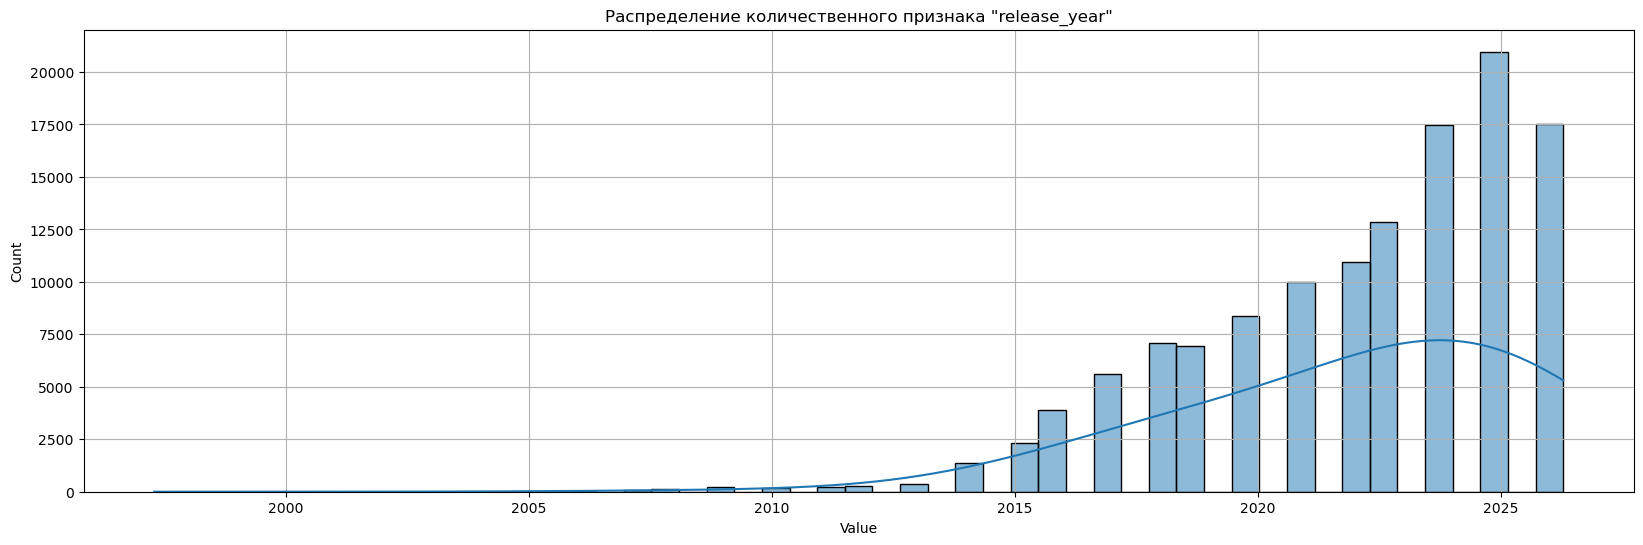

In [24]:
plot_quant_distribution(data=df, column="release_year")

#### Анализ столбца `num_genres`

Признак **количественный**.

Количество категорий признака num_genres: 18


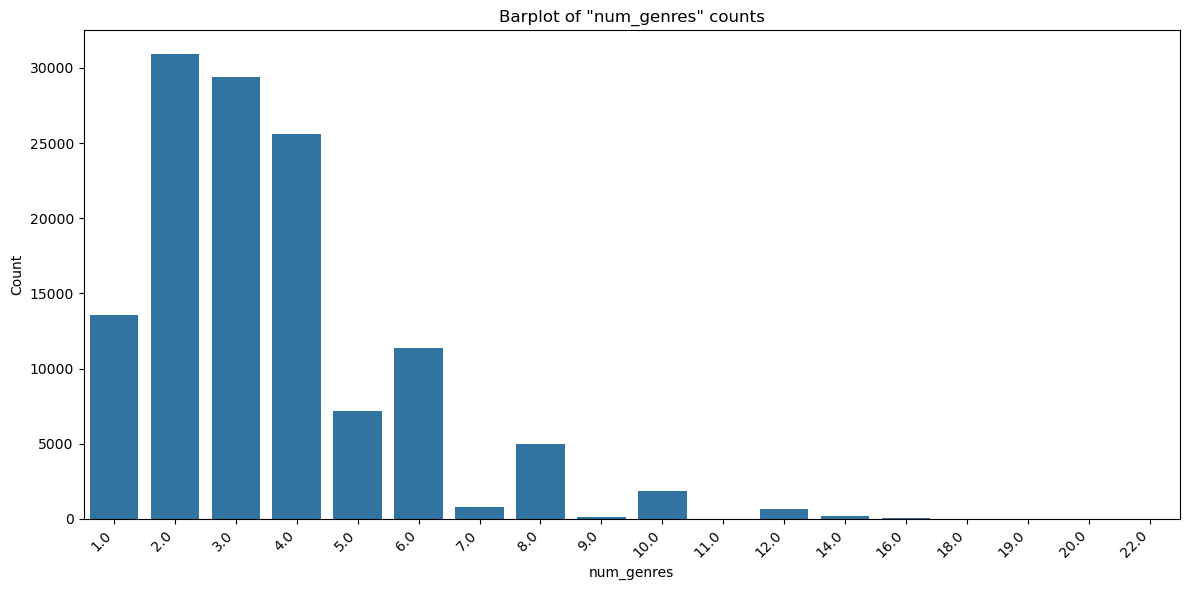

In [25]:
plot_cat_distribution(data=df, column_name="num_genres")

#### Расчет корреляции между количественными признаками

In [26]:
def compute_and_visualize_correlation_matrix(data: DataFrame, 
                                             columns: list[str]) -> None:
    """
    Вычисляет и визуализирует корреляционную матрицу для указанных 
    колонок в DataFrame PySpark.

    Args:
        data (DataFrame): DataFrame PySpark.
        columns (list[str]): Список колонок для вычисления корреляции.

    Returns:
        None
    """
    # Вычисление корреляционной матрицы
    corr_matrix = {}
    for col1 in columns:
        corr_matrix[col1] = {}
        for col2 in columns:
            corr_value = data.select(corr(col1, col2)).collect()[0][0]
            corr_matrix[col1][col2] = corr_value

    # Преобразование корреляционной матрицы в DataFrame Pandas для визуализации
    corr_matrix_pd = pd.DataFrame(corr_matrix)

    # Построение и визуализация корреляционной матрицы
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix_pd, annot=True, cmap='coolwarm', linewidths=0.5)
    plt.title('Correlation Matrix')
    plt.show()

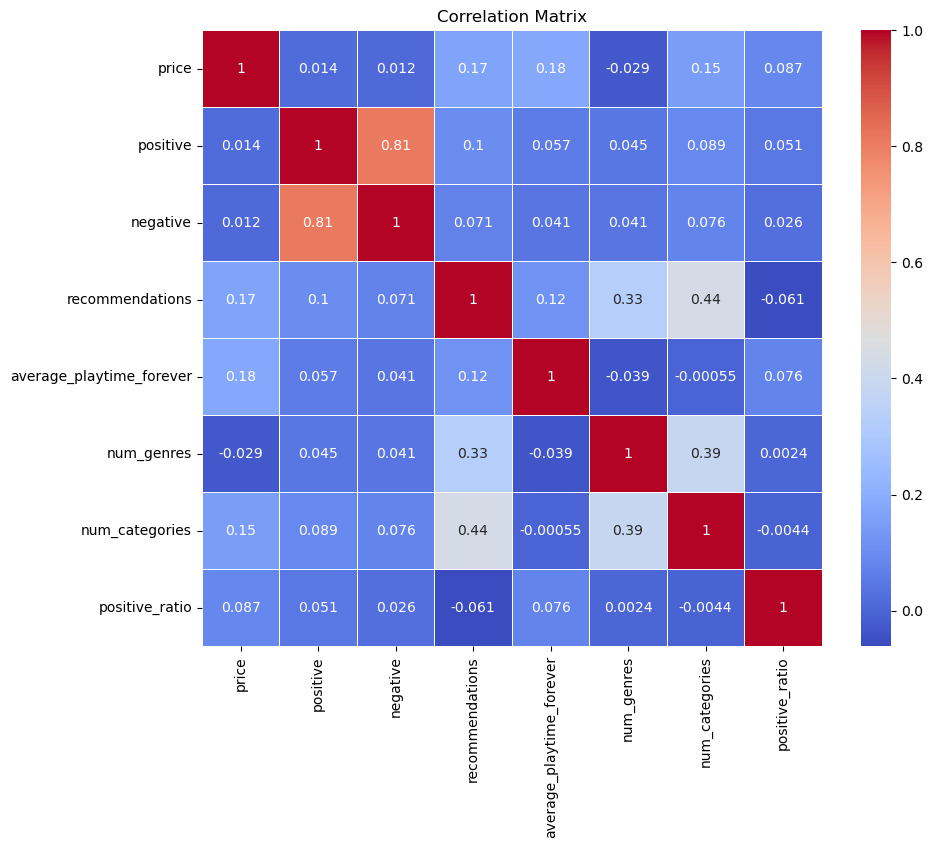

In [27]:
compute_and_visualize_correlation_matrix(
    data=df, columns=[
        "price", "positive", "negative", "recommendations",
        "average_playtime_forever", "num_genres", "num_categories",
        "positive_ratio"
    ]
)

Корреляционная матрица демонстрирует наличие корреляции между некоторыми количественными признаками.

### Выводы по анализу датасета Steam Games

1. **Цены:** Большинство игр имеют цену до $20, при этом значительная часть игр бесплатна.

2. **Жанры:** Наиболее популярные жанры - Indie, Action и Casual.

3. **Отзывы:** Средний процент положительных отзывов составляет около 87%.

4. **Корреляции:**
   - Сильная корреляция между количеством положительных отзывов и негативными отзывами
   - Количество жанров слабо коррелирует с популярностью игр
   - Цена слабо коррелирует с популярностью

In [28]:
# Сохраняем обработанный датафрейм
df.write.mode("overwrite").parquet("steam_games_processed.parquet")
print("Данные сохранены в Parquet: steam_games_processed.parquet")

Данные сохранены в Parquet: steam_games_processed.parquet


In [29]:
spark.stop()
print("Сессия Spark остановлена")

✅ Сессия Spark остановлена
